# Practical 07 – Logistic Regression Classification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report


In [2]:
raw = load_breast_cancer(as_frame=True)
X = raw.data
y = raw.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [3]:
def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    scores = {'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, pos_label=0), 'Recall': recall_score(y_test, pred, pos_label=0), 'F1': f1_score(y_test, pred, pos_label=0)}
    print(name, scores)
    print(classification_report(y_test, pred, target_names=['Malignant', 'Benign']))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1], display_labels=['Malignant', 'Benign'], cmap='Blues')
    plt.title(name)
    plt.show()
    return scores


Logistic Regression {'Accuracy': 0.9824561403508771, 'Precision': 0.9761904761904762, 'Recall': 0.9761904761904762, 'F1': 0.9761904761904762}
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



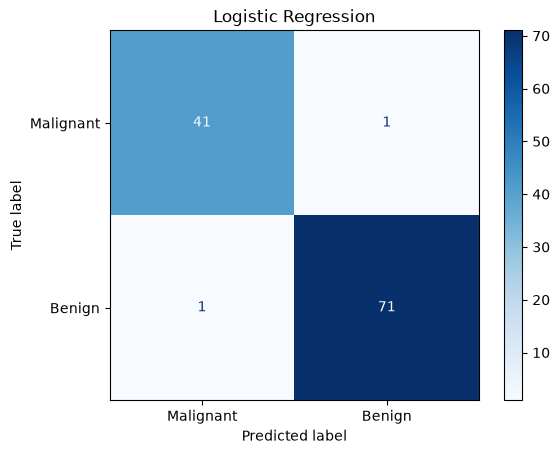

{'Accuracy': 0.9824561403508771,
 'Precision': 0.9761904761904762,
 'Recall': 0.9761904761904762,
 'F1': 0.9761904761904762}

In [4]:
from sklearn.linear_model import LogisticRegression
model = Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=2000, random_state=42))])
evaluate('Logistic Regression', model)
